In [4]:
import sys
from pathlib import Path

project_root = Path("/mnt/x/segmentation_cfos")
sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import torch
from sklearn.metrics import confusion_matrix, classification_report
import pickle
import time
from tqdm import tqdm

from src.models.unet_3d_monai import UNet3D_MONAI
from src.inference.predict import load_model

print("✅ Bibliothèques importées")



✅ Bibliothèques importées


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

checkpoint_dir = project_root / "outputs" / "checkpoints"
model_path = checkpoint_dir / "best_model.pth"
pred_dir = project_root / "outputs" / "evaluation" / "predictions"
metrics_dir = project_root / "outputs" / "evaluation" / "metrics"
history_path = project_root / "outputs" / "training_history.pkl"

metrics_dir.mkdir(parents=True, exist_ok=True)

In [ ]:
model = load_model(model_path, UNet3D_MONAI, device, init_features=32)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

In [ ]:
history = None
history_csv_path = project_root / "outputs" / "logs_v2" / "training_history.csv"
if history_csv_path.exists():
    import pandas as pd
    df_history = pd.read_csv(history_csv_path)
    history = df_history.to_dict('list')
else:
    old_history_path = project_root / "outputs" / "training_history.pkl"
    if old_history_path.exists():
        with open(old_history_path, 'rb') as f:
            history = pickle.load(f)    
    else:
        print(" Fichier d'historique non trouvé")

In [ ]:
pred_files = sorted(pred_dir.glob("*.npz"))
all_images = []
all_masks = []
all_preds = []
for f in tqdm(pred_files, desc="Chargement des prédictions"):
    data = np.load(f)
    all_images.append(data["image"])
    all_masks.append(data["mask"])
    all_preds.append(data["prediction"])

In [14]:
def compute_metrics(y_true, y_pred, threshold=0.5):
    """Calcule les métriques pour un échantillon"""
    # Binariser la prédiction
    y_pred_bin = (y_pred > threshold).astype(np.float32)
    
    # Vrais positifs, faux positifs, faux négatifs
    tp = np.sum((y_true == 1) & (y_pred_bin == 1))
    fp = np.sum((y_true == 0) & (y_pred_bin == 1))
    fn = np.sum((y_true == 1) & (y_pred_bin == 0))
    tn = np.sum((y_true == 0) & (y_pred_bin == 0))
    
    # Métriques
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0
    
    return {
        'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
        'precision': precision, 'recall': recall, 'f1': f1,
        'iou': iou, 'accuracy': accuracy
    }



In [15]:
def visualize_prediction_3d(image, mask, prediction, sample_name, slice_index=None, save_path=None):
    """
    Visualise une prédiction en 3D avec 3 slices différentes
    """
    if slice_index is None:
        slice_index = image.shape[0] // 2
    
    # Binariser la prédiction
    pred_bin = (prediction > 0.5).astype(np.float32)
    
    # Normaliser l'image
    img_norm = image / image.max() if image.max() > 0 else image
    
    # Slices à afficher: centre, centre-10%, centre+10%
    z_center = slice_index
    z_offsets = [-max(1, int(image.shape[0] * 0.1)), 0, max(1, int(image.shape[0] * 0.1))]
    z_slices = [max(0, min(image.shape[0]-1, z_center + offset)) for offset in z_offsets]
    
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    
    for row, z in enumerate(z_slices):
        # Image
        axes[row, 0].imshow(img_norm[z, :, :], cmap='gray')
        axes[row, 0].set_title(f'Image - Slice {z}')
        axes[row, 0].axis('off')
        
        # Mask réel
        axes[row, 1].imshow(mask[z, :, :], cmap='gray')
        axes[row, 1].set_title(f'Mask Réel - {np.sum(mask[z,:,:])} voxels')
        axes[row, 1].axis('off')
        
        # Prédiction
        axes[row, 2].imshow(pred_bin[z, :, :], cmap='gray')
        axes[row, 2].set_title(f'Prédiction - {np.sum(pred_bin[z,:,:])} voxels')
        axes[row, 2].axis('off')
        
        # Overlay: Image + Mask réel (vert) + Prédiction (rouge)
        overlay = np.stack([img_norm[z], img_norm[z], img_norm[z]], axis=-1)
        # Mask réel en vert
        overlay[mask[z] > 0, 0] *= 0.3
        overlay[mask[z] > 0, 1] = 1.0
        overlay[mask[z] > 0, 2] *= 0.3
        # Prédiction en rouge (transparent)
        overlay[pred_bin[z] > 0, 0] = np.maximum(overlay[pred_bin[z] > 0, 0], 0.7)
        overlay[pred_bin[z] > 0, 1] = 0.2
        overlay[pred_bin[z] > 0, 2] = 0.2
        axes[row, 3].imshow(overlay)
        axes[row, 3].set_title('Overlay (vert=GT, rouge=Pred)')
        axes[row, 3].axis('off')
    
    plt.suptitle(f'Échantillon: {sample_name}', fontsize=14)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300)
    plt.show()



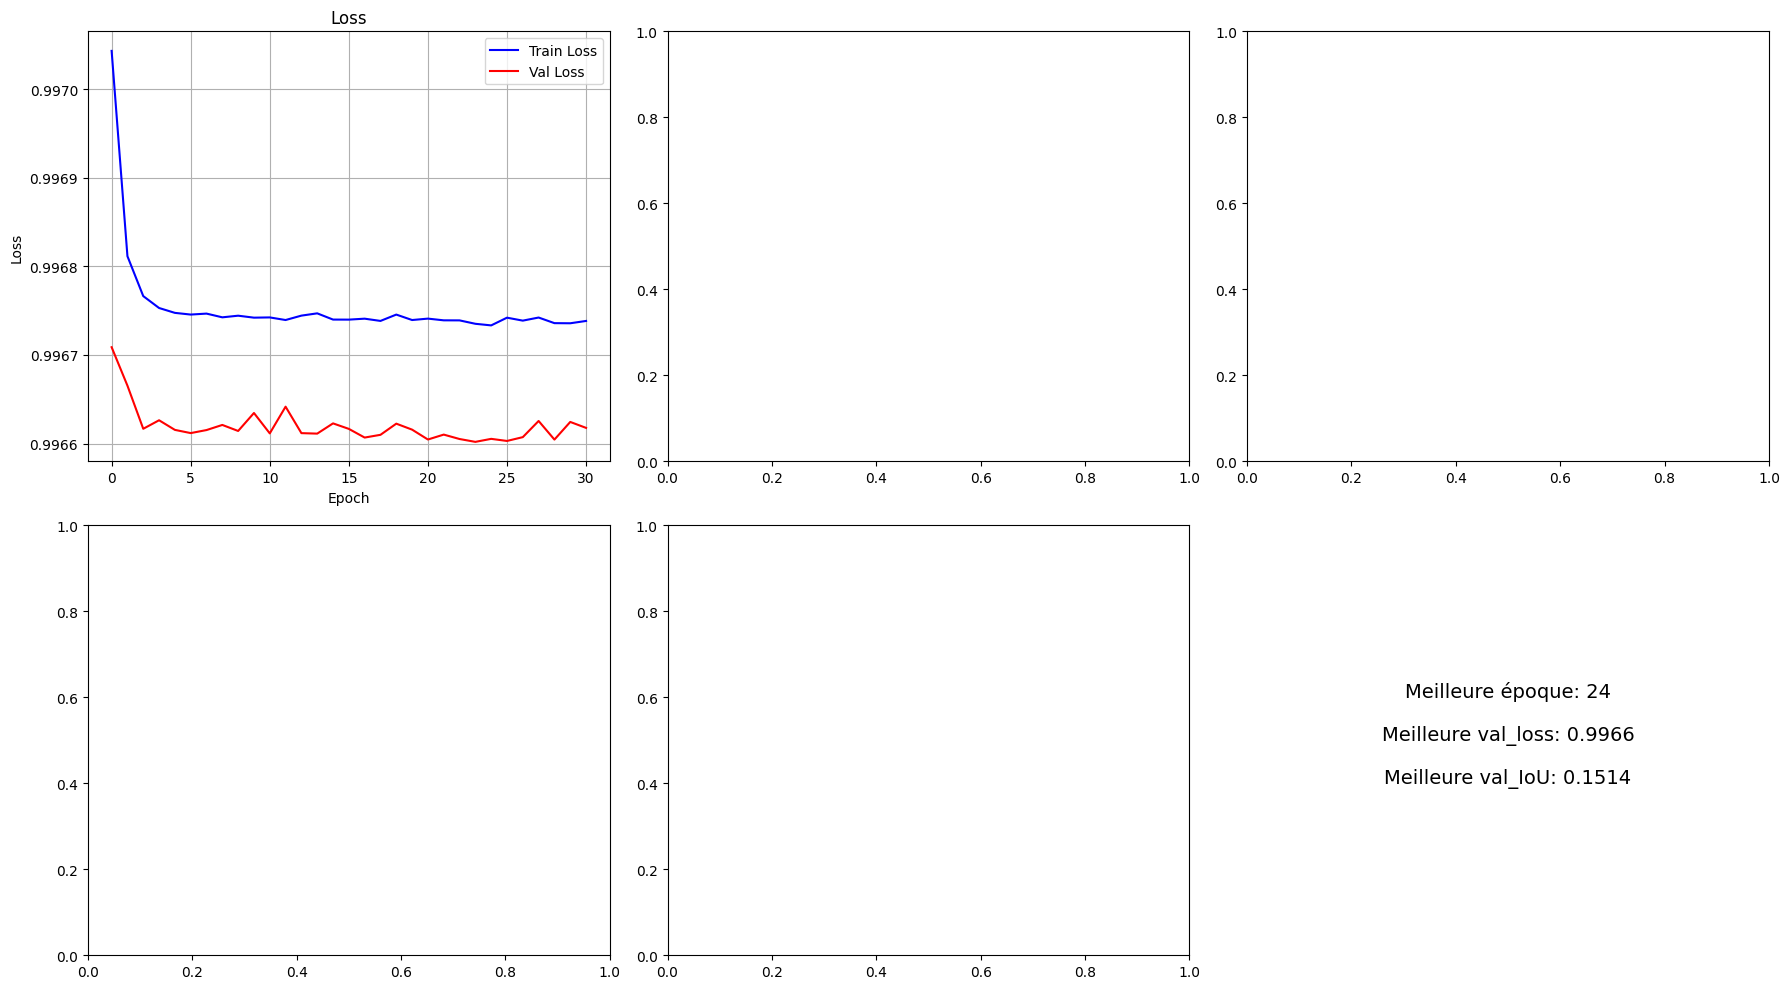

✅ Courbes sauvegardées: training_curves.png


In [16]:
if history:
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # Loss
    axes[0, 0].plot(history['train_loss'], label='Train Loss', color='blue')
    axes[0, 0].plot(history['val_loss'], label='Val Loss', color='red')
    axes[0, 0].set_title('Loss')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].legend()
    axes[0, 0].grid(True)
    
    # Accuracy
    if 'train_acc' in history:
        axes[0, 1].plot(history['train_acc'], label='Train Acc', color='blue')
        axes[0, 1].plot(history['val_acc'], label='Val Acc', color='red')
        axes[0, 1].set_title('Accuracy')
        axes[0, 1].set_xlabel('Epoch')
        axes[0, 1].set_ylabel('Accuracy')
        axes[0, 1].legend()
        axes[0, 1].grid(True)
    
    # IoU / Dice
    if 'train_iou' in history:
        axes[0, 2].plot(history['train_iou'], label='Train IoU', color='blue')
        axes[0, 2].plot(history['val_iou'], label='Val IoU', color='red')
        axes[0, 2].set_title('IoU (Intersection over Union)')
        axes[0, 2].set_xlabel('Epoch')
        axes[0, 2].set_ylabel('IoU')
        axes[0, 2].legend()
        axes[0, 2].grid(True)
    
    # Temps par époque
    if 'epoch_times' in history:
        axes[1, 0].bar(range(len(history['epoch_times'])), history['epoch_times'])
        axes[1, 0].set_title('Temps par époque')
        axes[1, 0].set_xlabel('Epoch')
        axes[1, 0].set_ylabel('Temps (secondes)')
        axes[1, 0].grid(True)
        axes[1, 0].axhline(y=np.mean(history['epoch_times']), color='red', linestyle='--', label='Moyenne')
        axes[1, 0].legend()
    
    # Temps cumulé
    if 'epoch_times' in history:
        axes[1, 1].plot(np.cumsum(history['epoch_times']))
        axes[1, 1].set_title('Temps cumulé')
        axes[1, 1].set_xlabel('Epoch')
        axes[1, 1].set_ylabel('Temps (secondes)')
        axes[1, 1].grid(True)
        axes[1, 1].text(0.5, 0.9, f"Total: {sum(history['epoch_times'])/60:.1f} min", 
                       transform=axes[1, 1].transAxes, ha='center')
    
    # Meilleure époque
    if 'val_loss' in history:
        best_epoch = np.argmin(history['val_loss'])
        best_val_loss = history['val_loss'][best_epoch]
        axes[1, 2].text(0.5, 0.6, f"Meilleure époque: {best_epoch+1}", 
                        ha='center', fontsize=14)
        axes[1, 2].text(0.5, 0.5, f"Meilleure val_loss: {best_val_loss:.4f}", 
                        ha='center', fontsize=14)
        if 'val_iou' in history:
            best_iou = history['val_iou'][best_epoch]
            axes[1, 2].text(0.5, 0.4, f"Meilleure val_IoU: {best_iou:.4f}", 
                            ha='center', fontsize=14)
        axes[1, 2].axis('off')
    
    plt.tight_layout()
    plt.savefig(metrics_dir / "training_curves.png", dpi=300)
    plt.show()
    print(" Courbes sauvegardées: training_curves.png")
else:
    print(" Pas d'historique disponible pour les courbes")



📊 Métriques par échantillon:
   sample  precision  recall        f1       iou  accuracy
0       0   0.016591     1.0  0.032641  0.016591  0.945282
1       1   0.000505     1.0  0.001010  0.000505  0.932102
2       2   0.013975     1.0  0.027565  0.013975  0.925446
3       3   0.002084     1.0  0.004159  0.002084  0.603622
4       4   0.008240     1.0  0.016346  0.008240  0.690552

📊 Métriques moyennes:
precision    0.007177
recall       0.945884
f1           0.014150
iou          0.007176
accuracy     0.778497
dtype: float64
✅ Métriques sauvegardées
Matrice de confusion (Fond, Neurone):
[[4076495 1161304]
 [     10    5071]]


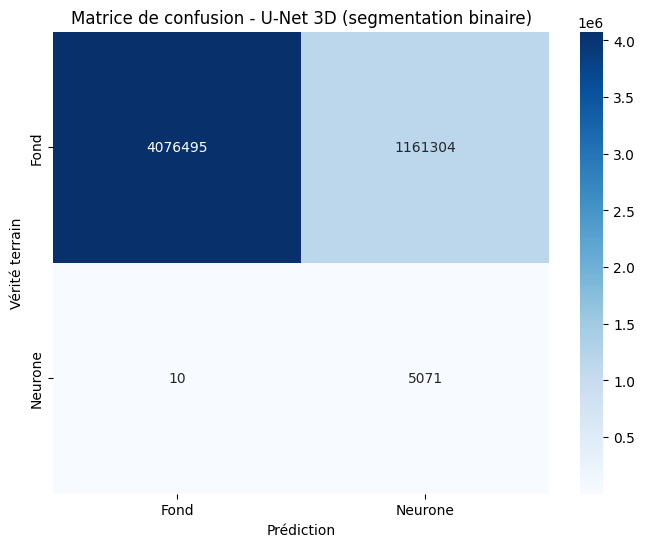

✅ Matrice de confusion sauvegardée
📊 Rapport de classification:
              precision    recall  f1-score       support
Fond           0.999998  0.778284  0.875319  5.237799e+06
Neurone        0.004348  0.998032  0.008658  5.081000e+03
accuracy       0.778497  0.778497  0.778497  7.784969e-01
macro avg      0.502173  0.888158  0.441988  5.242880e+06
weighted avg   0.999033  0.778497  0.874479  5.242880e+06
✅ Rapport de classification sauvegardé

Échantillon 1: sample_0000


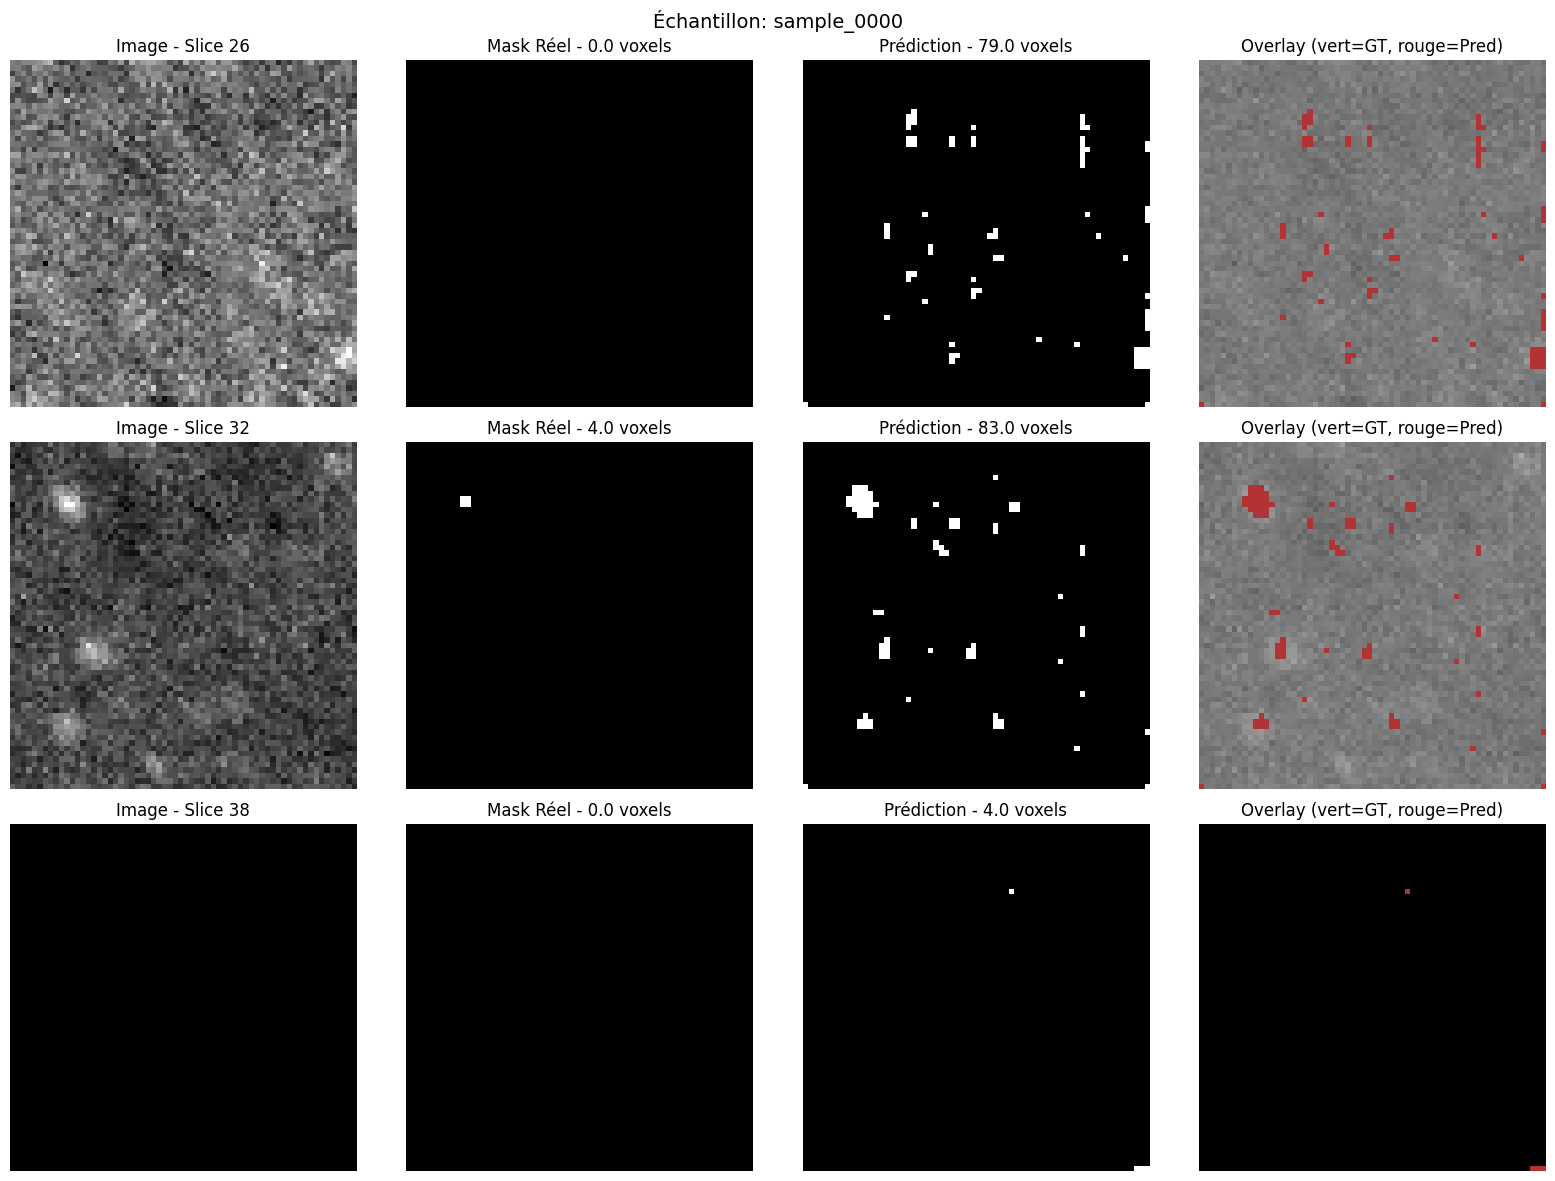


Échantillon 2: sample_0001


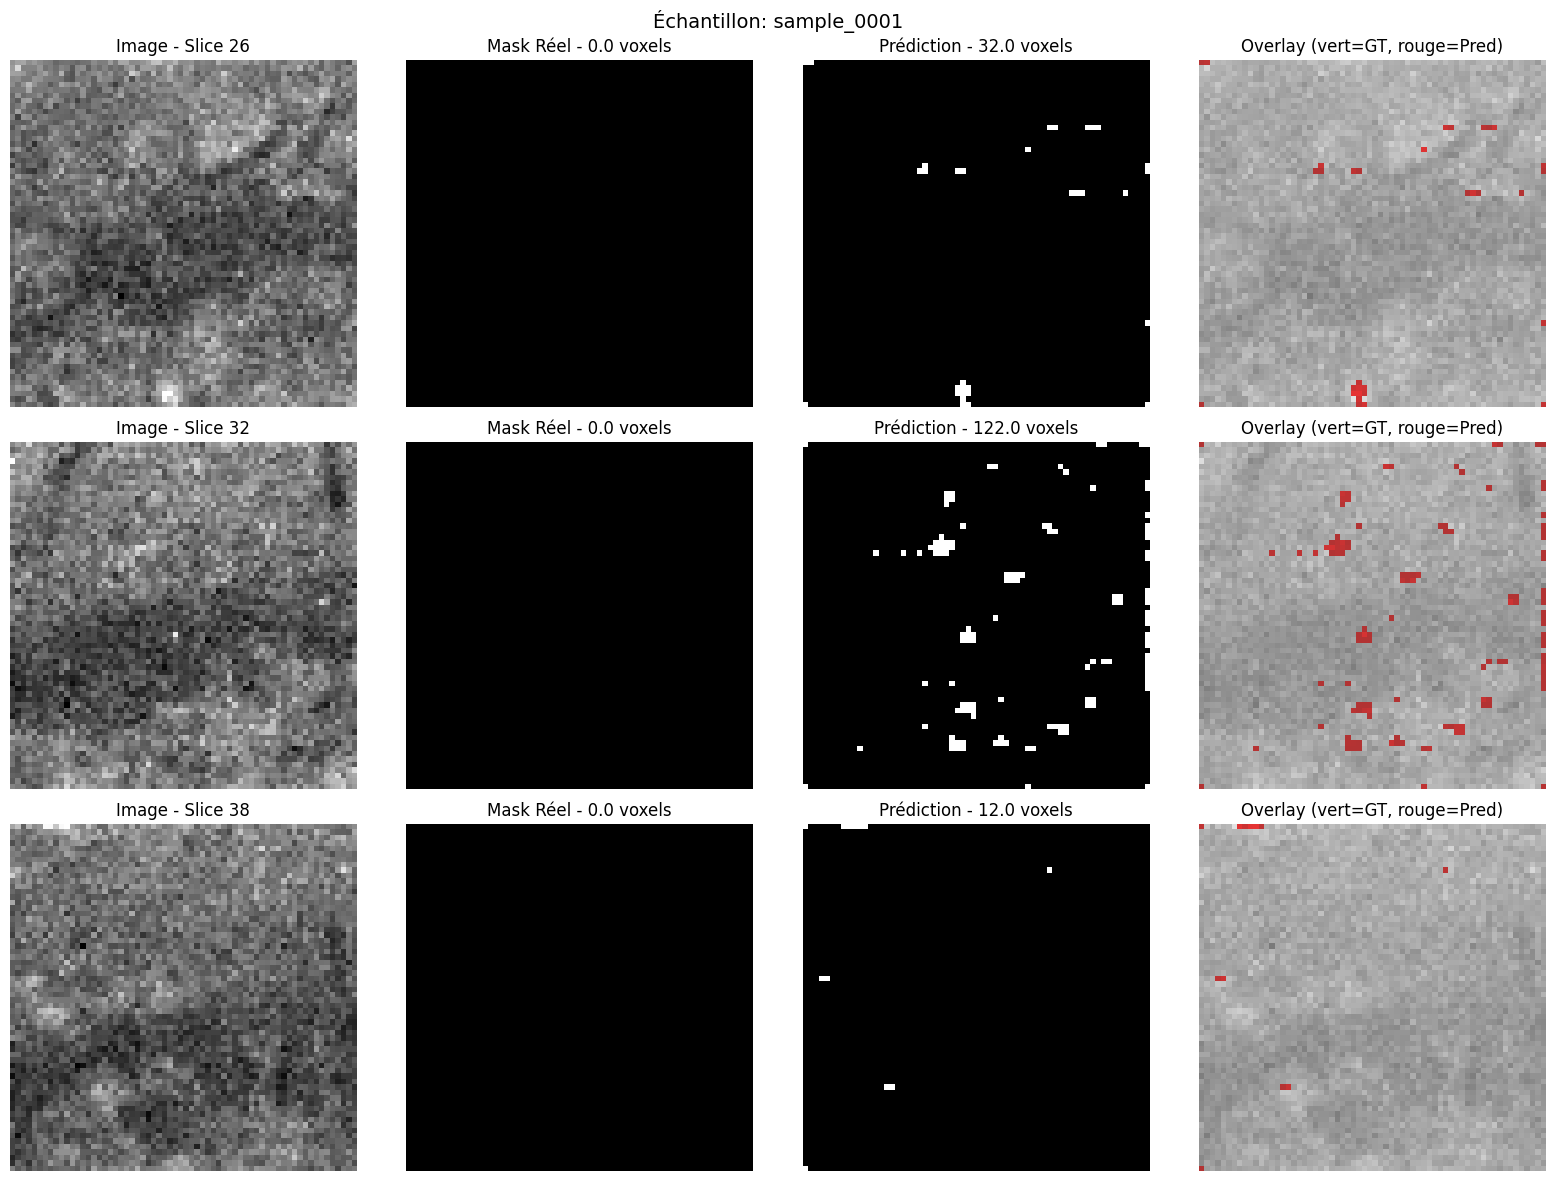


Échantillon 3: sample_0002


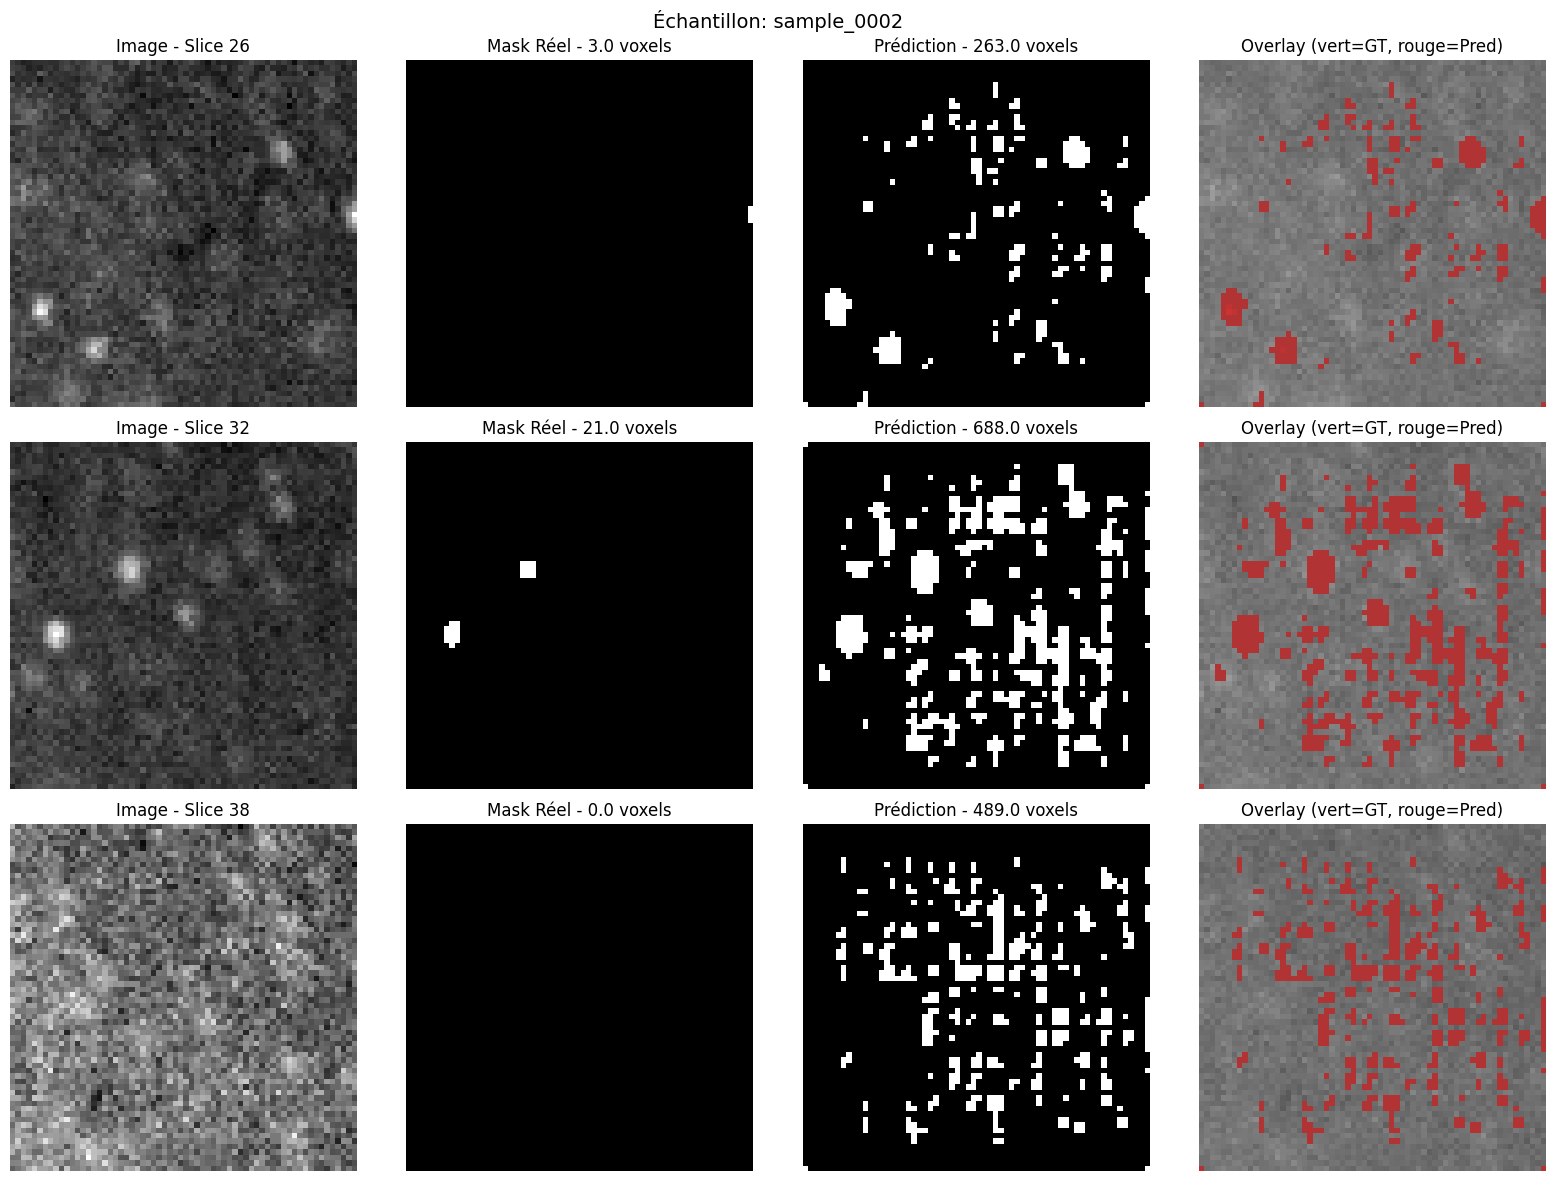


Échantillon 4: sample_0003


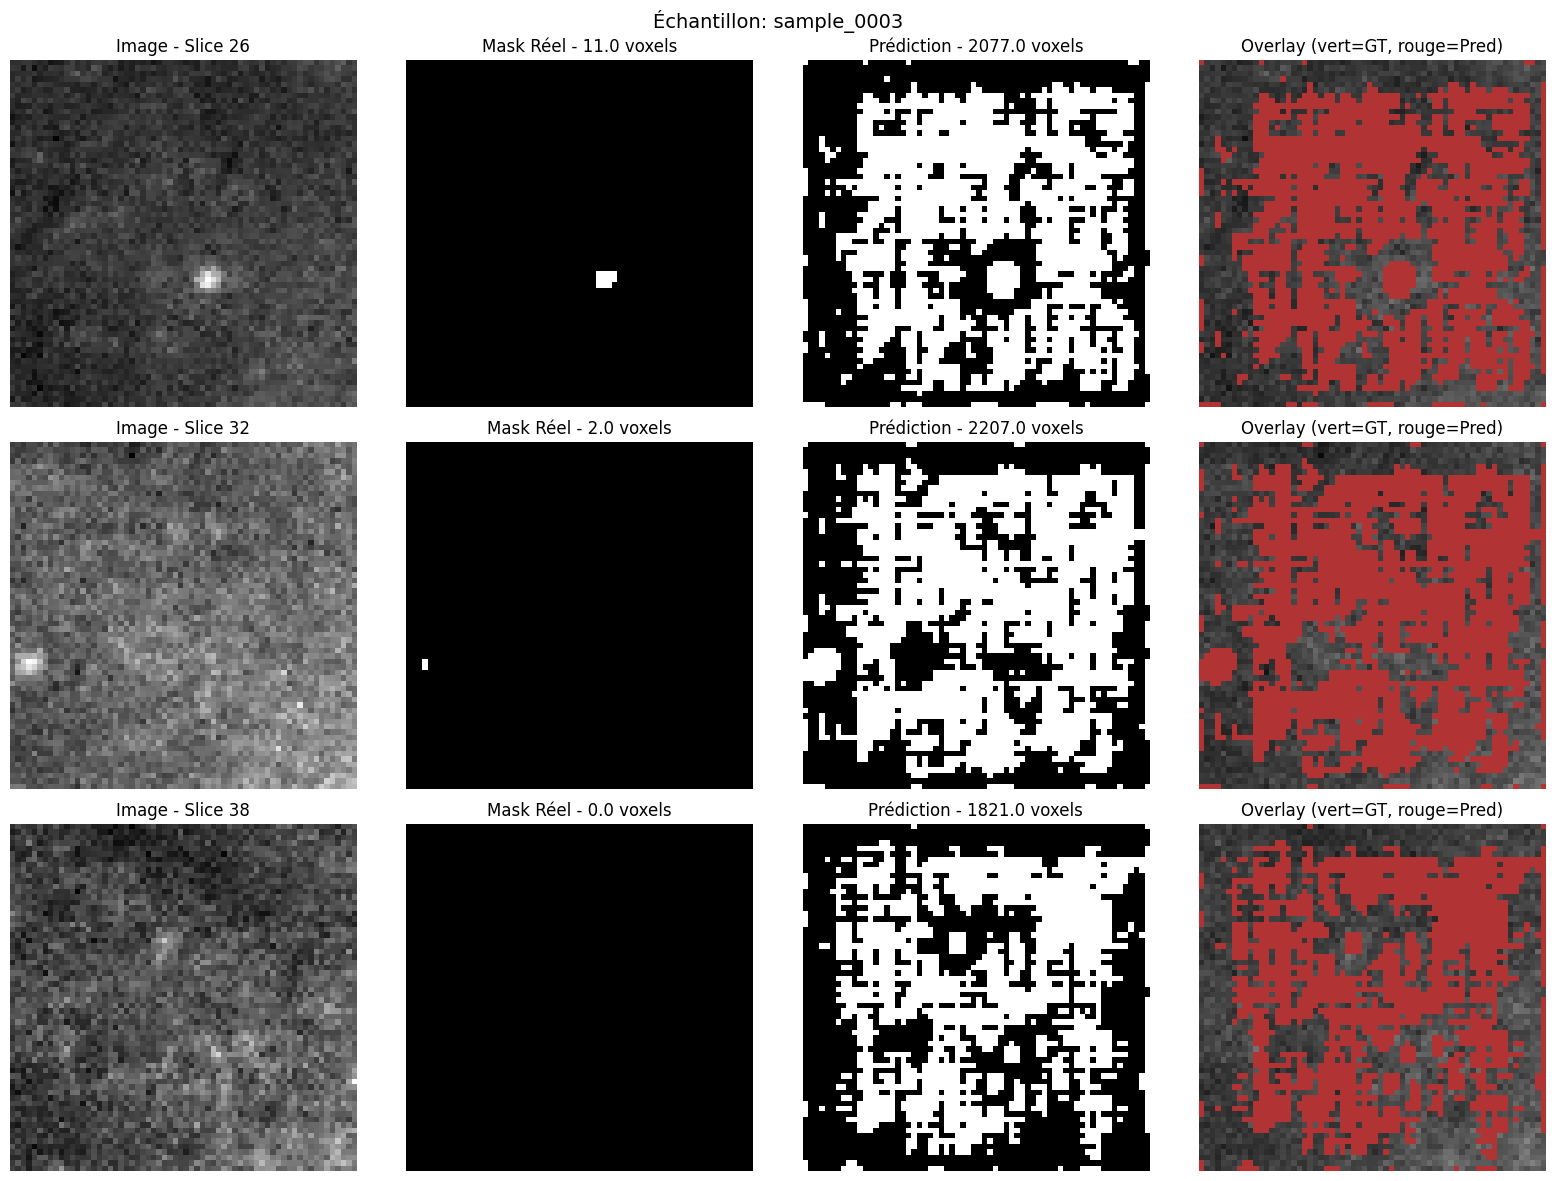

✅ Visualisations sauvegardées

📊 RÉSUMÉ FINAL - U-Net 3D (segmentation binaire)
📐 Architecture: U-Net 3D
   - Couches: 5 niveaux
   - Canaux initiaux: 32
   - Classes: 2 (fond, neurone)
   - Total paramètres: 19,219,984

📊 Performance sur l'ensemble de test (20 échantillons):
   - Précision moyenne: 0.0072
   - Rappel moyen: 0.9459
   - F1-score moyen: 0.0141
   - IoU moyen: 0.0072
   - Accuracy moyenne: 0.7785

📁 Résultats sauvegardés dans: /mnt/x/segmentation_cfos/outputs/evaluation/metrics
✅ Résumé final sauvegardé: model_summary.csv


In [17]:
all_metrics = []
for i, (img, mask, pred) in enumerate(zip(all_images, all_masks, all_preds)):
    metrics = compute_metrics(mask, pred)
    metrics['sample'] = i
    all_metrics.append(metrics)

# DataFrame des métriques
df_metrics = pd.DataFrame(all_metrics)
print(" Métriques par échantillon:")
print(df_metrics[['sample', 'precision', 'recall', 'f1', 'iou', 'accuracy']].head())

# Métriques moyennes
avg_metrics = df_metrics[['precision', 'recall', 'f1', 'iou', 'accuracy']].mean()
print("\n Métriques moyennes:")
print(avg_metrics)

# Sauvegarde
df_metrics.to_csv(metrics_dir / "metrics_per_sample.csv", index=False)
avg_metrics_df = pd.DataFrame([avg_metrics])
avg_metrics_df.to_csv(metrics_dir / "metrics_average.csv", index=False)
print("Métriques sauvegardées")

all_preds_flat = np.concatenate([(p > 0.5).flatten().astype(np.int32) for p in all_preds])
all_masks_flat = np.concatenate([m.flatten().astype(np.int32) for m in all_masks])

cm = confusion_matrix(all_masks_flat, all_preds_flat, labels=[0, 1])
print("Matrice de confusion (Fond, Neurone):")
print(cm)

# Visualiser la matrice de confusion
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Fond', 'Neurone'],
            yticklabels=['Fond', 'Neurone'])
ax.set_xlabel('Prédiction')
ax.set_ylabel('Vérité terrain')
ax.set_title('Matrice de confusion - U-Net 3D (segmentation binaire)')
plt.savefig(metrics_dir / "confusion_matrix.png", dpi=300)
plt.show()
print(" Matrice de confusion sauvegardée")

report = classification_report(all_masks_flat, all_preds_flat, 
                               target_names=['Fond', 'Neurone'], 
                               output_dict=True)
df_report = pd.DataFrame(report).transpose()
print(" Rapport de classification:")
print(df_report)

# Sauvegarde
df_report.to_csv(metrics_dir / "classification_report.csv")
print(" Rapport de classification sauvegardé")

sample_indices = [0, 1, 2, 3]

for i in sample_indices:
    if i < len(pred_files):
        data = np.load(pred_files[i])
        sample_name = pred_files[i].stem
        print(f"\n{'='*60}")
        print(f"Échantillon {i+1}: {sample_name}")
        print(f"{'='*60}")
        visualize_prediction_3d(
            data["image"], 
            data["mask"], 
            data["prediction"], 
            sample_name,
            save_path=metrics_dir / f"prediction_{sample_name}.png"
        )

print(" Visualisations sauvegardées")

print("\n" + "="*60)
print(" RÉSUMÉ FINAL - U-Net 3D (segmentation binaire)")
print("="*60)

print(f" Architecture: U-Net 3D")
print(f"   - Couches: 5 niveaux")
print(f"   - Canaux initiaux: 32")
print(f"   - Classes: {2} (fond, neurone)")
print(f"   - Total paramètres: {total_params:,}")

print(f"\n Performance sur l'ensemble de test ({len(pred_files)} échantillons):")
print(f"   - Précision moyenne: {avg_metrics['precision']:.4f}")
print(f"   - Rappel moyen: {avg_metrics['recall']:.4f}")
print(f"   - F1-score moyen: {avg_metrics['f1']:.4f}")
print(f"   - IoU moyen: {avg_metrics['iou']:.4f}")
print(f"   - Accuracy moyenne: {avg_metrics['accuracy']:.4f}")

print(f"\n Résultats sauvegardés dans: {metrics_dir}")
summary = {
    'Modèle': 'U-Net 3D (MONAI)',
    'Classification': 'Binaire (Fond vs Neurone)',
    'Canaux initiaux': 32,
    'Total paramètres': total_params,
    'Précision moyenne': avg_metrics['precision'],
    'Rappel moyen': avg_metrics['recall'],
    'F1-score moyen': avg_metrics['f1'],
    'IoU moyen': avg_metrics['iou'],
    'Accuracy moyenne': avg_metrics['accuracy']
}

df_summary = pd.DataFrame([summary])
df_summary.to_csv(metrics_dir / "model_summary.csv", index=False)
print(" Résumé final sauvegardé: model_summary.csv")